# Ensemble ConvNeXt dan Vision Transformer untuk Klasifikasi Citra Wajah Asli dan Palsu dengan Test-Time Augmentation

~ By HmsterBerkacamataHitamBwaPiPiw

- Veiron Vaya Yarief
- Nabila Putri Azhari
- Nasywa Kamila

# Problem Statement

Seiring dengan pesatnya perkembangan teknologi, sistem *face recognition* telah banyak diterapkan dalam berbagai sektor, seperti autentikasi perangkat, sistem absensi, hingga verifikasi identitas pada layanan keuangan. Meskipun memberikan kemudahan dan efisiensi, sistem ini masih memiliki kerentanan terhadap serangan keamanan, salah satunya adalah *face spoofing*.

*Face spoofing* merupakan bentuk serangan yang bertujuan untuk mengelabui sistem pengenalan wajah dengan memanfaatkan media visual, seperti foto cetak, tampilan wajah pada layar, masker, mannequin, maupun objek lain yang menyerupai wajah manusia. Serangan ini menjadi tantangan serius karena dapat mengecoh model jika tidak dilengkapi dengan mekanisme deteksi keaslian (*liveness detection*).

Permasalahan utama dalam penelitian ini adalah bagaimana membangun model yang mampu membedakan secara akurat antara wajah asli (*realperson*) dan berbagai bentuk representasi wajah palsu (*fake*), dalam kondisi dataset yang kompleks dan tidak terstruktur.

Tantangan yang dihadapi meliputi:
- Ketidakseimbangan distribusi kelas (*class imbalance*)
- Keberadaan data dengan label tidak akurat (*mislabeled data*)
- Variasi intraclass yang tinggi
- Variasi resolusi citra yang tidak seragam
- Kompleksitas visual antar kelas yang memiliki kemiripan tinggi

Oleh karena itu, diperlukan pendekatan yang robust dan mampu melakukan generalisasi dengan baik terhadap berbagai variasi data.

# Dataset Description

Dataset yang digunakan dalam penelitian ini merupakan dataset klasifikasi citra wajah yang terdiri dari **1652 gambar**, yang terbagi ke dalam enam kelas utama:

| Class            | Jumlah |
|------------------|--------|
| fake_mannequin   | 224    |
| fake_mask        | 278    |
| fake_printed     | 118    |
| fake_screen      | 229    |
| fake_unknown     | 338    |
| realperson       | 465    |

Dataset ini dirancang untuk merepresentasikan berbagai skenario *face spoofing* di dunia nyata, dengan karakteristik sebagai berikut:

### 🔹 Jenis Kelas
- **realperson**: wajah manusia asli
- **fake_mask**: wajah menggunakan masker (silikon, kain, dll)
- **fake_mannequin**: wajah dari mannequin atau patung
- **fake_printed**: wajah dari foto cetak
- **fake_screen**: wajah yang ditampilkan melalui layar
- **fake_unknown**: objek lain yang menyerupai wajah (pareidolia, lukisan, dll)

### 🔹 Karakteristik Dataset
Dataset memiliki beberapa tantangan utama:
- Distribusi kelas tidak seimbang
- Terdapat mislabeled data
- Variasi intraclass tinggi (pose, lighting, background)
- Resolusi citra tidak seragam (rendah hingga sangat tinggi)
- Overlap visual antar kelas

### 🔹 Tujuan Penggunaan
Dataset ini digunakan untuk:
- Menguji kemampuan model dalam membedakan wajah asli vs palsu
- Mengevaluasi robustness terhadap variasi visual
- Mengukur kemampuan generalisasi model pada data kompleks

# Exploratory Data Analysis (EDA)

Tahap Exploratory Data Analysis (EDA) dilakukan untuk memahami karakteristik dataset serta mengidentifikasi permasalahan yang dapat mempengaruhi performa model.

---

### 🔹 1. Class Imbalance

Distribusi kelas pada dataset menunjukkan ketidakseimbangan yang signifikan antar kelas.

- Kelas **realperson** memiliki jumlah data terbesar  
- Kelas **fake_printed** memiliki jumlah paling sedikit  

Ketidakseimbangan ini berpotensi menyebabkan:
- Model bias terhadap kelas mayoritas
- Performa rendah pada kelas minoritas

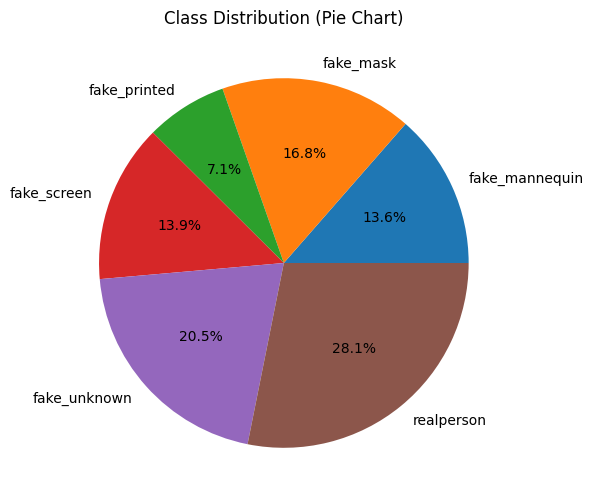

---

### 🔹 2. Mislabeled Data

Ditemukan sejumlah data dengan label yang tidak sesuai (mislabeled), berdasarkan inspeksi visual.

Contoh:
- `printed_095` → seharusnya *fake_unknown*  
- `mannequin_002` → seharusnya *fake_mask*  
- `unknown_002` → seharusnya *realperson*  

Permasalahan ini menyebabkan:
- Noise pada data training  
- Model belajar pola yang tidak konsisten  
- Penurunan kemampuan generalisasi  

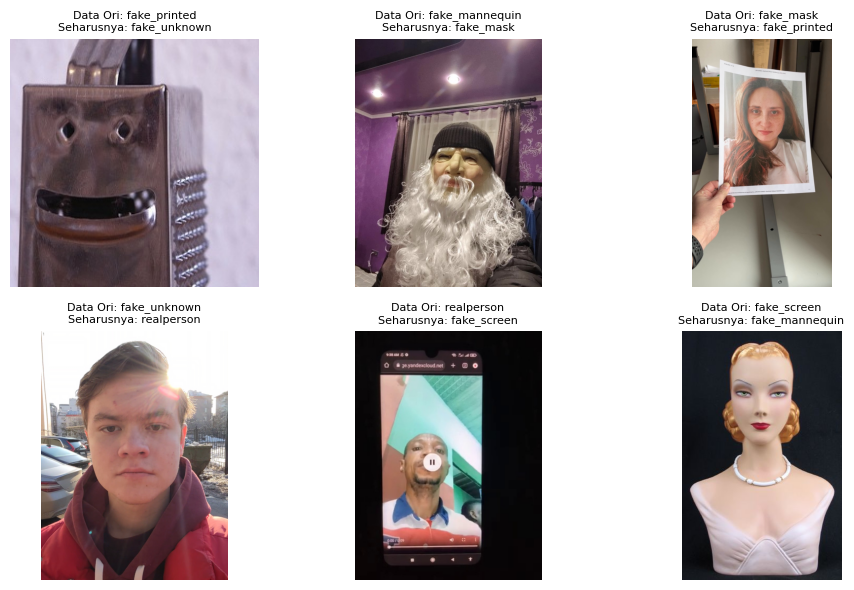

---

### 🔹 3. Variasi Intraclass

Setiap kelas memiliki variasi internal yang tinggi, meliputi:
- Perbedaan bentuk objek  
- Latar belakang  
- Kondisi pencahayaan  
- Pose dan orientasi  

Contoh:
- **fake_mask** → berbagai jenis masker (silikon, kain, dll)  
- **fake_mannequin** → patung, kepala mannequin, dll  
- **fake_unknown** → lukisan, pareidolia  

Dampak:
- Batas antar kelas menjadi tidak tegas  
- Meningkatkan kompleksitas klasifikasi  

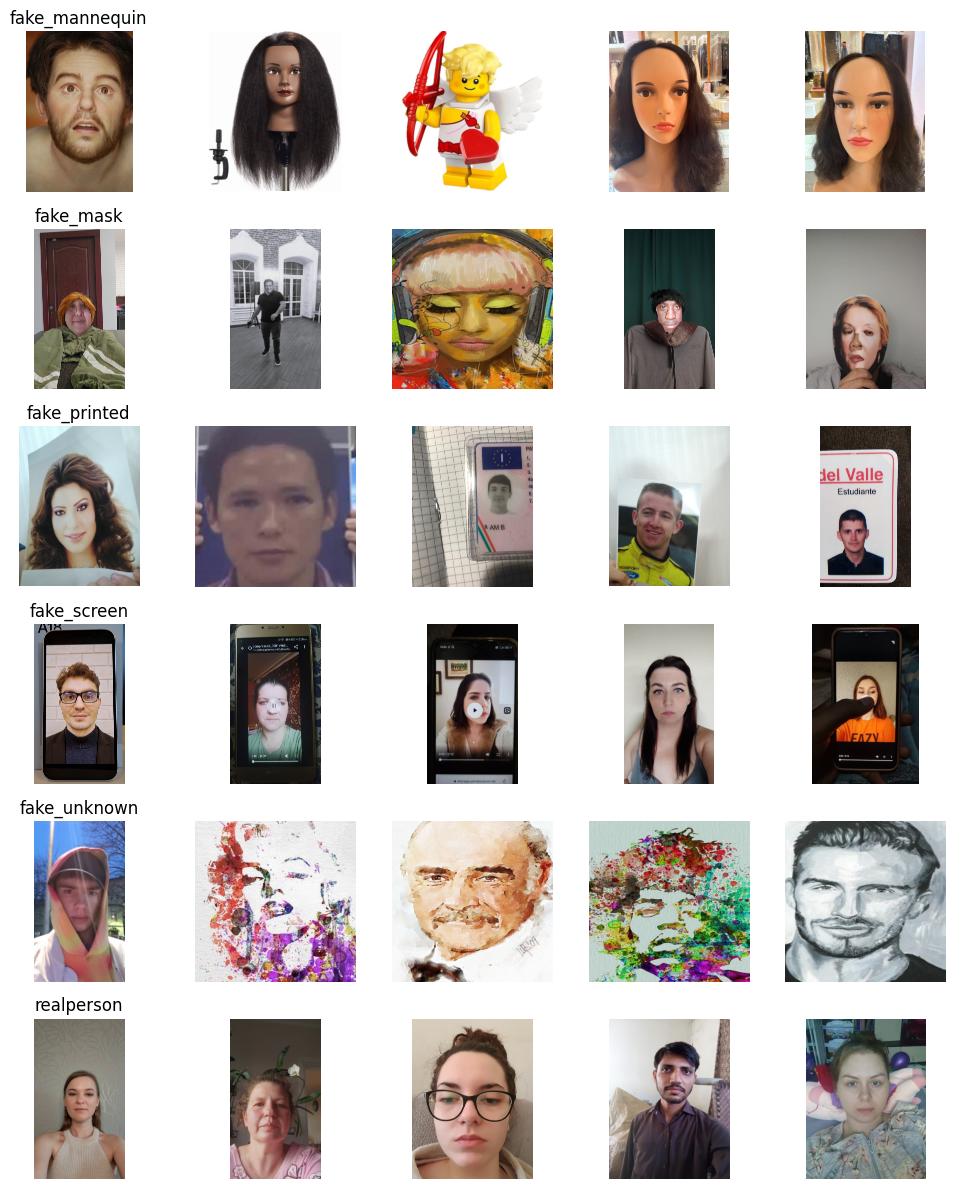

---

### 🔹 4. Variasi Resolusi

Dataset memiliki resolusi yang tidak seragam:
- Sebagian besar < 1000 px  
- Sebagian mencapai > 5000 px  

Dampak:
- Ketidakkonsistenan fitur yang dipelajari model  
- Citra resolusi rendah kehilangan detail  
- Citra resolusi tinggi memiliki informasi lebih kaya  

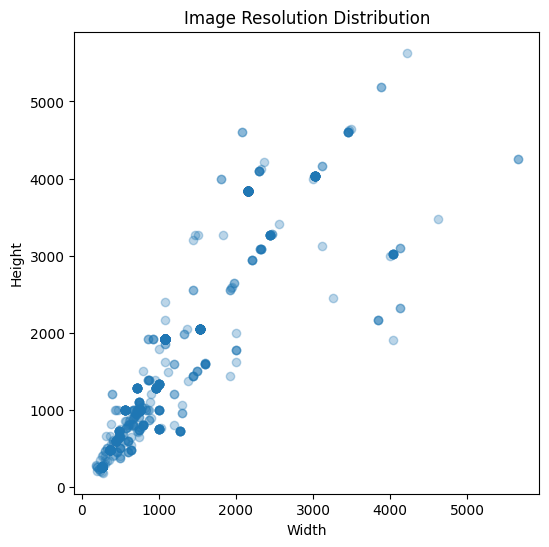

---

### 🔹 5. Ukuran Dataset

Dataset terdiri dari **1652 citra** dengan distribusi:

| Class            | Jumlah |
|------------------|--------|
| fake_mannequin   | 224    |
| fake_mask        | 278    |
| fake_printed     | 118    |
| fake_screen      | 229    |
| fake_unknown     | 338    |
| realperson       | 465    |

Meskipun jumlah data cukup besar:
- Tetap terdapat ketidakseimbangan distribusi  
- Memerlukan strategi training yang efisien  

---

### 🔹 Insight Utama

Dari hasil EDA, dapat disimpulkan bahwa dataset memiliki karakteristik:
- Tidak seimbang (*imbalanced*)
- Mengandung noise (*mislabeled data*)
- Variasi visual tinggi (*intraclass variation*)
- Resolusi tidak seragam  

Hal ini menunjukkan bahwa:
> Dataset termasuk **complex real-world dataset**, sehingga diperlukan pendekatan yang robust seperti augmentasi, TTA, dan ensemble.

# Library & Dependencies

Pada bagian ini dilakukan import berbagai library yang digunakan dalam proses pengolahan data, pelatihan model, serta evaluasi.

Library yang digunakan meliputi:
- **Data processing**: `numpy`, `pandas`
- **Visualisasi**: `matplotlib`, `seaborn`
- **Image processing**: `opencv`, `PIL`
- **Deep learning**: `torch`, `timm`
- **Augmentasi**: `albumentations`
- **Machine learning utilities**: `sklearn`
- **Data handling**: `Dataset`, `DataLoader`
- **Utilities**: `os`, `glob`, `tqdm`, `random`

Penggunaan kombinasi library ini memungkinkan pembangunan pipeline end-to-end, mulai dari eksplorasi data hingga evaluasi model.

# Pra Pemrosesan Data

Tahap prapemrosesan data dilakukan untuk mengatasi berbagai permasalahan yang ditemukan pada tahap Exploratory Data Analysis (EDA), seperti ketidakseimbangan kelas, variasi resolusi, serta tingginya variasi intraclass.

Selain itu, teknik augmentasi diterapkan untuk meningkatkan kemampuan generalisasi model terhadap variasi data yang kompleks.

---

### 🔹 Training

#### 1. Pembersihan Data Manual
Dilakukan proses pembersihan data untuk meningkatkan kualitas dataset, meliputi:
- Koreksi terhadap data yang memiliki label tidak sesuai (*mislabeled*)
- Penyesuaian distribusi data melalui duplikasi terkontrol pada kelas minoritas

Pendekatan ini bertujuan untuk memperkaya representasi data tanpa mengubah karakteristik utama dataset.

---

#### 2. Offline Augmentation
Offline augmentation dilakukan sebelum training dan menghasilkan data tambahan yang disimpan secara permanen.

Fokus augmentasi:
- Kelas **fake_screen**

Teknik:
- **Center Cropping** → mengambil bagian tengah citra

Tujuan:
- Mengurangi pengaruh frame layar
- Menghasilkan variasi *fake_screen tanpa frame*
- Membantu model fokus pada objek utama (wajah)

---

#### 3. On-the-fly Augmentation
Augmentasi dilakukan secara dinamis selama proses training (tidak menambah jumlah data secara eksplisit).

Teknik yang digunakan:
- **Resize**
  - ConvNeXt: 256
  - ViT: 384  
  → Menyesuaikan kebutuhan arsitektur model

- **Horizontal Flip (p=0.5)**
  → Menambahkan variasi orientasi wajah

- **Center Crop (p=0.3)**
  → Mensimulasikan variasi zoom dan fokus objek

Tujuan:
- Meningkatkan robustness model
- Membantu model memahami variasi posisi, orientasi, dan skala

---

### 🔹 Test-Time Augmentation (TTA)

Pada tahap inference, digunakan Test-Time Augmentation (TTA) untuk meningkatkan stabilitas prediksi.

Pendekatan:
- Satu gambar → beberapa variasi transformasi

Transformasi yang digunakan:
- Resize (sesuai model)
- Horizontal Flip
- Center Crop

Setiap hasil prediksi kemudian digabungkan (ensemble) untuk menghasilkan output akhir.

---

### 🔹 Tujuan Prapemrosesan

Secara keseluruhan, tahap prapemrosesan bertujuan untuk:
- Mengurangi noise akibat mislabeled data
- Mengatasi ketidakseimbangan distribusi kelas
- Menstandarkan resolusi citra
- Meningkatkan kemampuan generalisasi model

Kombinasi antara **offline augmentation**, **on-the-fly augmentation**, dan **TTA** terbukti memberikan kontribusi signifikan dalam meningkatkan performa model pada dataset yang kompleks.

In [3]:
import os
import glob
import cv2
import torch
import random
import timm
import shutil

import numpy as np
import seaborn as sns
import pandas as pd
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, f1_score, confusion_matrix

import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# ConvNeXt

## Environment Setup & Data Acquisition

Pada tahap ini dilakukan konfigurasi lingkungan komputasi serta persiapan dataset yang akan digunakan dalam proses pelatihan.

### 🔹 Device Configuration
Menentukan penggunaan perangkat komputasi (GPU jika tersedia, jika tidak maka menggunakan CPU) untuk mempercepat proses training.

### 🔹 Path Configuration
Menentukan direktori utama yang digunakan, meliputi:
- Path dataset training dan testing
- Path file submission
- Direktori penyimpanan model hasil training

### 🔹 Class Definition
Mendefinisikan enam kelas utama dalam dataset:
- `fake_mannequin`
- `fake_mask`
- `fake_printed`
- `fake_screen`
- `fake_unknown`
- `realperson`

Selain itu, dibuat mapping:
- `label2id` → mengubah label menjadi angka
- `id2label` → mengembalikan angka ke label

### 🔹 Data Indexing
Melakukan iterasi pada seluruh folder dataset untuk:
- Mengambil path setiap gambar
- Mengasosiasikan label numerik sesuai kelasnya
- Menyusun dataset dalam bentuk DataFrame

Hasil akhir berupa DataFrame (`df`) yang berisi:
- path gambar
- label numerik

Struktur ini memudahkan proses splitting, training, dan evaluasi model pada tahap selanjutnya.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [5]:
BASE_PATH = "/kaggle/working/"  

TRAIN_PATH = "/kaggle/input/datasets/nasywak/dataset/ensemble1_dataset/train"
TEST_PATH = "/kaggle/input/datasets/nasywak/dataset/ensemble1_dataset/test"

SUBMISSION_PATH = "/kaggle/input/datasets/nasywak/sample-sub/samplesubmission.csv"
SAVE_DIR = os.path.join(BASE_PATH,"models/models_conv")
os.makedirs(SAVE_DIR, exist_ok=True)


In [6]:
WORKING_TRAIN = TRAIN_PATH
INPUT_TRAIN = TRAIN_PATH

print("Classes:", os.listdir(TRAIN_PATH))

Classes: ['fake_mask', 'fake_printed', 'realperson', 'fake_unknown', 'fake_screen', 'fake_mannequin']


In [7]:
classes = [
    "fake_mannequin",
    "fake_mask",
    "fake_printed",
    "fake_screen",
    "fake_unknown",
    "realperson"
]

label2id = {c:i for i,c in enumerate(classes)}
id2label = {i:c for c,i in label2id.items()}

In [8]:
data = []

for label in classes:
    folder = os.path.join(TRAIN_PATH, label)
    for img in os.listdir(folder):
        data.append({
            "path": os.path.join(folder, img),
            "label": label2id[label]
        })

df = pd.DataFrame(data)
print("Total samples:", len(df))

Total samples: 1773


## Data Augmentation & Test-Time Augmentation (TTA)

Pada tahap ini diterapkan berbagai teknik augmentasi untuk meningkatkan variasi data serta robustness model terhadap perubahan visual.

### 🔹 Training Augmentation
Augmentasi pada data training dilakukan menggunakan `albumentations` dengan tujuan:
- Menstandarkan ukuran citra
- Menambahkan variasi orientasi dan skala

Transformasi yang digunakan:
- **Resize (256×256)** → memastikan ukuran input konsisten
- **Horizontal Flip (p=0.5)** → memperkenalkan variasi orientasi kiri/kanan
- **Center Crop (p=0.3)** → mensimulasikan variasi zoom dan fokus objek

Pendekatan ini membantu model belajar fitur yang lebih general dan tidak sensitif terhadap posisi objek.

---

### 🔹 Test-Time Augmentation (TTA)
Pada tahap inference, digunakan beberapa variasi transformasi untuk satu citra input:

- Resize (baseline)
- Horizontal Flip
- Center Crop + Resize

Setiap variasi menghasilkan prediksi yang berbeda, yang kemudian dapat digabungkan (ensemble) untuk meningkatkan stabilitas hasil.

TTA berfungsi sebagai:
> *"ensemble pada level input"*

---

### 🔹 Test Transform
Transformasi pada data test hanya berupa:
- **Resize (256×256)**

Hal ini dilakukan untuk menjaga konsistensi input tanpa menambahkan variasi tambahan.

---

### 🔹 No Augmentation
Digunakan sebagai baseline tanpa augmentasi, hanya:
- Resize (256×256)

---

### 🔹 Visualisasi Augmentasi
Untuk memahami efek dari augmentasi, dilakukan visualisasi:
- 1 gambar asli per kelas
- Beberapa hasil transformasi (TTA)

Tujuan visualisasi:
- Memastikan augmentasi bekerja sesuai harapan
- Melihat variasi yang dihasilkan
- Menghindari transformasi yang merusak informasi penting

Visualisasi ini membantu memastikan bahwa augmentasi meningkatkan kualitas data tanpa mengubah label secara semantik.


Visualizing class: fake_mannequin


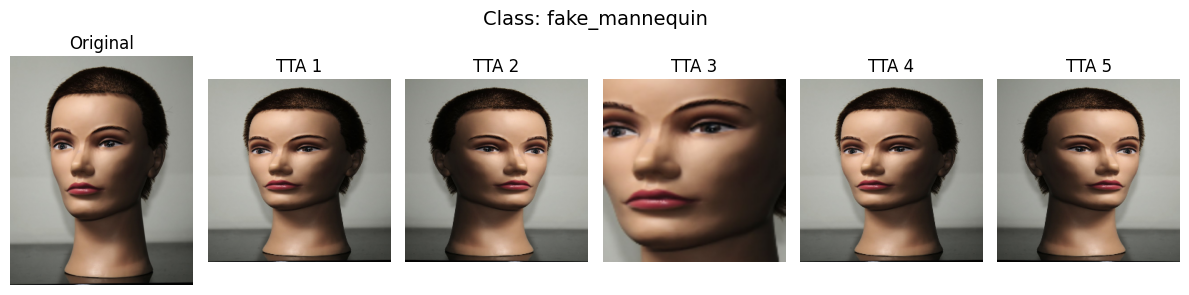


Visualizing class: fake_mask


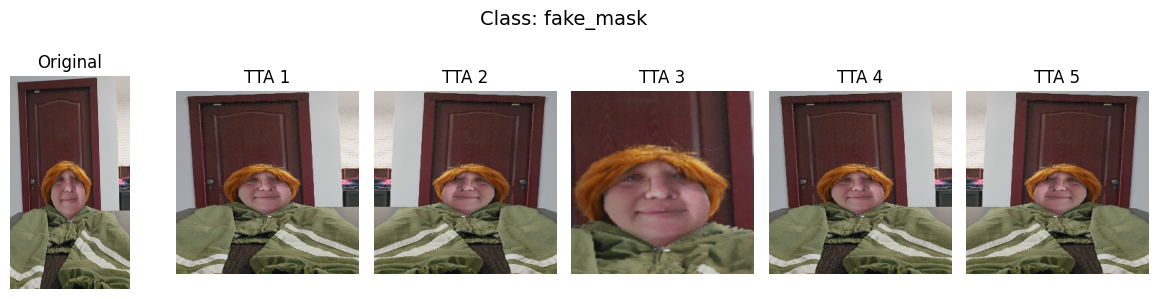


Visualizing class: fake_printed


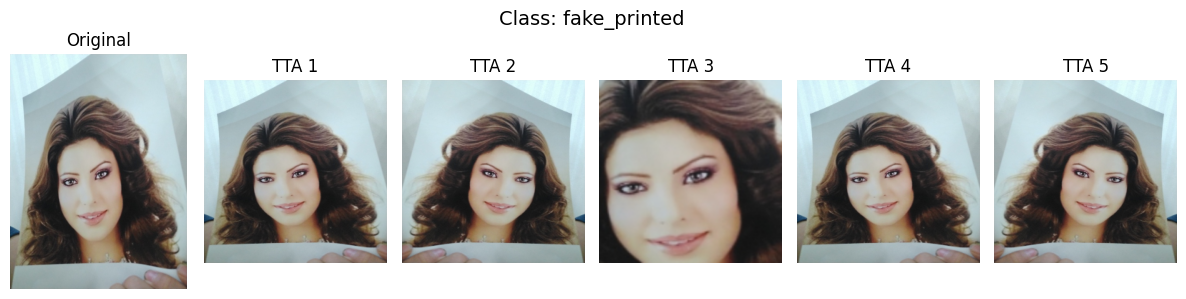


Visualizing class: fake_screen


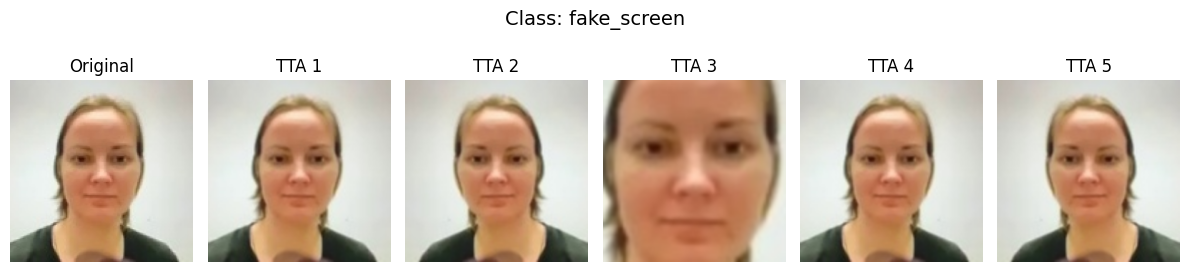


Visualizing class: fake_unknown


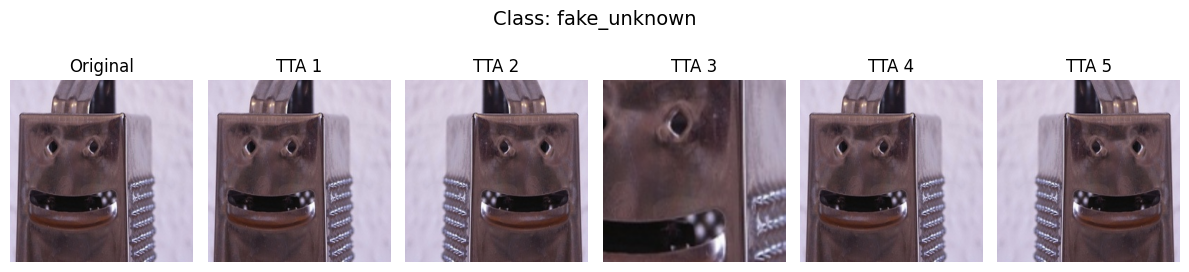


Visualizing class: realperson


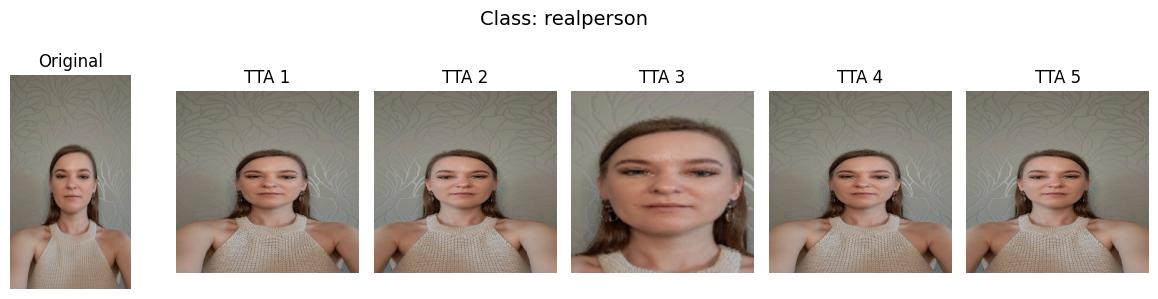

In [9]:
train_tfms = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.CenterCrop(128, 128, p=0.3),
    A.Resize(256, 256),
])

tta_tfms = [
    A.Compose([A.Resize(256, 256)]),

    A.Compose([
        A.Resize(256, 256),
        A.HorizontalFlip(p=1.0),
    ]),

    A.Compose([
        A.Resize(256, 256),
        A.CenterCrop(128, 128),
        A.Resize(256, 256),
    ]),
]

test_tfms = A.Compose([
    A.Resize(256, 256)
])

no_aug_tfms = A.Compose([
    A.Resize(256, 256)
])

# ===== VISUALIZATION PER CLASS =====
num_aug = 5  # number of augmented samples per class

for label in classes:
    print(f"\nVisualizing class: {label}")

    # get one sample image from this class
    sample_row = df[df["label"] == label2id[label]].iloc[0]
    img_path = sample_row["path"]

    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 3))
    plt.suptitle(f"Class: {label}", fontsize=14)

    # original
    plt.subplot(1, num_aug + 1, 1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis("off")

    # augmented versions
    for i in range(num_aug):
        tta = tta_tfms[i % len(tta_tfms)]
        aug = tta(image=image)["image"]
    
        plt.subplot(1, num_aug + 1, i + 2)
        plt.imshow(aug)
        plt.title(f"TTA {i+1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Dataset, Training Setup, dan Validation

Pada bagian ini dilakukan implementasi dataset custom, pengaturan reproducibility, serta fungsi training dan evaluasi model.

---

### 🔹 Custom Dataset (PyTorch)

Kelas `FaceDataset` digunakan untuk memuat data citra beserta labelnya secara dinamis.

Fitur utama:
- Membaca gambar menggunakan OpenCV dan mengubah ke format RGB
- Menerapkan **augmentasi berbeda secara kondisional**:
  - Kelas `fake_screen` → menggunakan transformasi khusus tanpa augmentasi tambahan
  - Kelas lain → menggunakan augmentasi training
- Normalisasi citra menggunakan standar ImageNet
- Mengubah format citra menjadi `(C, H, W)` untuk PyTorch

Pendekatan ini memungkinkan penyesuaian preprocessing berdasarkan karakteristik masing-masing kelas.

---

### 🔹 Reproducibility

Fungsi `set_seed()` digunakan untuk memastikan hasil eksperimen dapat direproduksi dengan:
- Mengatur seed pada `random`, `numpy`, dan `torch`
- Mengaktifkan mode deterministik pada CUDA

---

### 🔹 Stratified K-Fold

Digunakan `StratifiedKFold` untuk membagi dataset menjadi beberapa fold dengan:
- Distribusi label yang seimbang pada setiap fold
- Mengurangi bias akibat pembagian data

---

### 🔹 Training Function

Fungsi `train_one_epoch()` digunakan untuk:
- Melatih model selama satu epoch
- Menghitung loss dan akurasi training
- Melakukan backpropagation dan update parameter model

---

### 🔹 Validation Function

Fungsi `validate()` digunakan untuk:
- Mengevaluasi performa model pada data validasi
- Menghitung:
  - **Accuracy**
  - **F1-score (macro)** → penting untuk dataset tidak seimbang

---

### 🔹 Tujuan Implementasi

Struktur ini dirancang untuk:
- Mendukung pipeline training yang fleksibel
- Menjaga konsistensi preprocessing
- Memastikan evaluasi yang adil pada dataset kompleks

In [10]:
class FaceDataset(Dataset):
    def __init__(self, df, transforms=None, no_aug_transforms=None, fake_screen_label=None):
        self.df = df.reset_index(drop=True)
        self.transforms = transforms
        self.no_aug_transforms = no_aug_transforms
        self.fake_screen_label = fake_screen_label

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img = cv2.imread(row.path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        label = row.label

        # 🔥 conditional transform
        if label == self.fake_screen_label:
            if self.no_aug_transforms:
                img = self.no_aug_transforms(image=img)["image"]
        else:
            if self.transforms:
                img = self.transforms(image=img)["image"]

        img = img.astype(np.float32) / 255.0

        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = (img - mean) / std

        img = np.transpose(img, (2,0,1))

        return torch.tensor(img, dtype=torch.float32), torch.tensor(label)

In [11]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # untuk reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

## ConvNext Training (K-Fold Strategy)

Pada tahap ini dilakukan proses pelatihan model menggunakan pendekatan **Stratified K-Fold Cross Validation** untuk meningkatkan robustness dan mengurangi bias pembagian data.

---

### 🔹 K-Fold Training

Dataset dibagi menjadi beberapa fold menggunakan `StratifiedKFold`, sehingga:
- Distribusi kelas tetap seimbang pada setiap fold
- Model dilatih dan divalidasi pada subset data yang berbeda

Setiap fold menghasilkan satu model yang disimpan untuk digunakan pada tahap ensemble.

---

### 🔹 Data Loading

Untuk setiap fold:
- Data training menggunakan augmentasi (`train_tfms`)
- Data validasi hanya menggunakan transformasi dasar (`test_tfms`)
- Data dimuat menggunakan `DataLoader` dengan batch size 32

---

### 🔹 Model

Model yang digunakan:
- **ConvNeXt Small (pretrained)**
- Fine-tuned untuk klasifikasi 6 kelas

Model ini dipilih karena kemampuannya dalam menangkap fitur lokal seperti tekstur dan detail visual.

---

### 🔹 Training Configuration

- **Loss Function**: CrossEntropyLoss  
- **Optimizer**: AdamW  
- **Learning Rate**: 1e-4  
- **Epoch**: 2 (eksperimen awal)

---

### 🔹 Training Process

Untuk setiap epoch:
1. Model dilatih menggunakan data training
2. Dilakukan evaluasi pada data validasi
3. Menghitung:
   - Training Accuracy
   - Validation F1-score

---

### 🔹 Model Selection

Model terbaik dipilih berdasarkan:
- **F1-score tertinggi pada validation set**

Jika performa meningkat:
- Model disimpan dalam format `.pth`
- Path model disimpan untuk digunakan pada tahap ensemble

---

### 🔹 Tujuan Pendekatan

Pendekatan ini bertujuan untuk:
- Mengurangi variansi model
- Meningkatkan generalisasi
- Menghasilkan beberapa model yang dapat digabungkan melalui ensemble

In [12]:
skf = StratifiedKFold(n_splits=7, shuffle=True, random_state=42)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for imgs, labels in tqdm(loader):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(imgs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), correct / total


def validate(model, loader):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)

            outputs = model(imgs)
            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    f1 = f1_score(all_labels, all_preds, average="macro")

    return acc, f1

print(df["path"].head())

0    /kaggle/input/datasets/nasywak/dataset/ensembl...
1    /kaggle/input/datasets/nasywak/dataset/ensembl...
2    /kaggle/input/datasets/nasywak/dataset/ensembl...
3    /kaggle/input/datasets/nasywak/dataset/ensembl...
4    /kaggle/input/datasets/nasywak/dataset/ensembl...
Name: path, dtype: object


In [13]:
EPOCHS = 12
fold_models = []

SAVE_PATH = SAVE_DIR
os.makedirs(SAVE_PATH, exist_ok=True)

for fold, (train_idx, val_idx) in enumerate(skf.split(df, df["label"])):

    print(f"\n========== FOLD {fold+1} ==========")

    train_df = df.iloc[train_idx]
    val_df = df.iloc[val_idx]

    train_dataset = FaceDataset(train_df, train_tfms)
    val_dataset = FaceDataset(val_df, test_tfms)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)

    model = timm.create_model(
        "convnext_small.fb_in22k_ft_in1k",
        pretrained=True,
        num_classes=6
    )

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=1e-4)

    best_f1 = 0

    for epoch in range(EPOCHS):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, val_f1 = validate(model, val_loader)

        print(f"Epoch {epoch+1} | Train Acc: {train_acc:.4f} | Val F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1

            model_path = f"{SAVE_PATH}/model_fold_{fold}.pth"
            torch.save(model.state_dict(), model_path)

            fold_models.append(model_path)


========== FOLD 1 ==========


model.safetensors:   0%|          | 0.00/201M [00:00<?, ?B/s]

100%|██████████| 48/48 [02:15<00:00,  2.83s/it]


Epoch 1 | Train Acc: 0.8216 | Val F1: 0.9519


100%|██████████| 48/48 [02:00<00:00,  2.52s/it]


Epoch 2 | Train Acc: 0.9625 | Val F1: 0.9705


... (158 outputs left out)

100%|██████████| 48/48 [01:57<00:00,  2.44s/it]


Epoch 11 | Train Acc: 0.9954 | Val F1: 0.9371


100%|██████████| 48/48 [01:58<00:00,  2.46s/it]


Epoch 12 | Train Acc: 0.9987 | Val F1: 0.9736


## Inference, Test-Time Augmentation (TTA), dan Ensemble 

Pada tahap ini dilakukan proses inferensi menggunakan model hasil training dengan pendekatan **Test-Time Augmentation (TTA)** dan **ensemble berbasis multi-fold**.

---

### 🔹 Persiapan Data Test

Data test diambil berdasarkan file submission yang berisi `id` gambar.  
Setiap ID dicocokkan dengan file gambar yang tersedia (`.jpg`, `.png`, `.jpeg`).

Dataset kemudian dibentuk dalam bentuk DataFrame yang berisi:
- Path gambar test

Selanjutnya dibuat `TestDataset` untuk:
- Membaca gambar
- Menerapkan transformasi dasar (resize)
- Normalisasi sesuai standar ImageNet

---

### 🔹 Test Dataset & DataLoader

- Dataset: `TestDataset`
- Transform: resize + normalization
- Batch size: 32

Data dimuat menggunakan `DataLoader` tanpa shuffle untuk menjaga urutan prediksi.

---

### 🔹 Inference per Fold

Setiap model hasil K-Fold digunakan untuk melakukan prediksi secara independen.

Langkah:
1. Load model dari file `.pth`
2. Set model ke mode evaluasi (`eval`)
3. Lakukan prediksi pada seluruh data test

Pendekatan ini menghasilkan beberapa prediksi dari model yang berbeda.

---

### 🔹 Test-Time Augmentation (TTA)

Untuk setiap batch input:
- Gambar dibuat beberapa variasi menggunakan transformasi TTA:
  - Resize (baseline)
  - Horizontal Flip
  - Center Crop

Setiap variasi:
1. Diproses ulang (denormalize → augment → normalize)
2. Dimasukkan ke model
3. Menghasilkan probabilitas prediksi

---

### 🔹 Aggregasi TTA

Hasil prediksi dari berbagai augmentasi digabungkan dengan:
- **Averaging probabilitas (mean)**

Tujuan:
- Mengurangi noise
- Meningkatkan stabilitas prediksi
- Menghasilkan prediksi yang lebih robust

---

### 🔹 Ensemble Antar Fold

Setelah TTA:
- Setiap fold menghasilkan probabilitas prediksi

Kemudian dilakukan:
- **Averaging antar fold (multi-model ensemble)**

Langkah:
1. Kumpulkan probabilitas dari semua fold
2. Hitung rata-rata
3. Ambil kelas dengan probabilitas tertinggi (`argmax`)

---

### 🔹 Output Final

- Label akhir dikonversi kembali dari ID ke nama kelas
- Disimpan dalam format submission `.csv`

---

### 🔹 Insight Metodologi

Pendekatan ini menggabungkan tiga jenis diversitas:

- **Data-level** → melalui TTA  
- **Model-level** → melalui K-Fold  
- **Prediction-level** → melalui ensemble  

Sehingga:
> Model tidak bergantung pada satu representasi input atau satu model saja.

---

### 🔹 Keuntungan Pendekatan

- Mengurangi variansi prediksi  
- Meningkatkan stabilitas hasil  
- Lebih robust terhadap noise dan variasi data  
- Meningkatkan kemampuan generalisasi  

---

### 🔹 Kesimpulan

Kombinasi **TTA + K-Fold + Ensemble** memungkinkan model:
- Melihat data dari berbagai perspektif  
- Menggabungkan keunggulan berbagai model  
- Menghasilkan prediksi yang lebih akurat dan konsisten  

In [14]:
submission_df = pd.read_csv(SUBMISSION_PATH)

test_paths = []
for img_id in submission_df["id"]:
    for ext in [".jpg", ".png", ".jpeg"]:
        path = os.path.join(TEST_PATH, img_id + ext)
        if os.path.exists(path):
            test_paths.append(path)
            break

test_df = pd.DataFrame({"path": test_paths})


class TestDataset(Dataset):
    def __init__(self, df, transforms=None):
        self.df = df
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = cv2.imread(self.df.iloc[idx].path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transforms:
            img = self.transforms(image=img)["image"]

        img = img.astype(np.float32) / 255.0

        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img = (img - mean) / std

        img = np.transpose(img, (2,0,1))

        return torch.tensor(img, dtype=torch.float32)

In [15]:
test_dataset = TestDataset(test_df, test_tfms)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

all_fold_preds = []

print("===== DEBUG START =====")

model_dir = f"{SAVE_DIR}"

model_files = [
    f for f in os.listdir(model_dir)
    if f.endswith(".pth") and f.startswith("model_fold_")
]

model_files = sorted(
    model_files,
    key=lambda x: int(x.split("_")[-1].split(".")[0])
)

print("Models:", model_files)
print("Total:", len(model_files))


# ===== INFERENCE PER FOLD =====
for fold_idx, model_name in enumerate(model_files):

    fold_path = os.path.join(model_dir, model_name)


    model = timm.create_model(
        "convnext_small.fb_in22k_ft_in1k",
        pretrained=False,
        num_classes=6
    )

    model.load_state_dict(torch.load(fold_path, map_location=device))

    model = model.to(device)
    model.eval()

    fold_preds = []

    with torch.no_grad():
        for imgs in test_loader:

            imgs = imgs.to(device)
            tta_preds = []

            for tta in tta_tfms:
                aug_imgs = []

                for img in imgs.cpu().numpy():
                    img = np.transpose(img, (1,2,0))

                    # denormalize
                    mean = np.array([0.485, 0.456, 0.406])
                    std = np.array([0.229, 0.224, 0.225])
                    img = (img * std) + mean
                    img = (img * 255).astype(np.uint8)

                    aug = tta(image=img)["image"]

                    # normalize
                    aug = aug.astype(np.float32) / 255.0
                    aug = (aug - mean) / std
                    aug = np.transpose(aug, (2,0,1))

                    aug_imgs.append(aug)

                aug_imgs = torch.from_numpy(np.stack(aug_imgs)).float().to(device)

                outputs = model(aug_imgs)
                probs = torch.softmax(outputs, dim=1)

                tta_preds.append(probs)

            # 🔥 average TTA predictions
            tta_preds = torch.stack(tta_preds).mean(0)

            fold_preds.append(tta_preds.cpu().numpy())

    fold_probs = np.concatenate(fold_preds)
    all_fold_preds.append(fold_probs)

    # optional: save per fold
    fold_labels = np.argmax(fold_probs, axis=1)

    fold_df = submission_df.copy()
    fold_df["label"] = [id2label[p] for p in fold_labels]

    fold_df.to_csv(os.path.join(SAVE_DIR, f"submission_fold_{fold_idx}.csv"), index=False)

    print(f"Saved submission_fold_{fold_idx}.csv")


# ===== FINAL ENSEMBLE =====
all_fold_preds = np.array(all_fold_preds)

final_probs = np.mean(all_fold_preds, axis=0)
final_preds = np.argmax(final_probs, axis=1)


# ===== FINAL SUBMISSION =====
submission_df["label"] = [id2label[p] for p in final_preds]

submission_df.to_csv(
    f"{SAVE_DIR}/submission_ensemble1.csv",
    index=False
)

print("Submission saved 🚀")

===== DEBUG START =====
Models: ['model_fold_0.pth', 'model_fold_1.pth', 'model_fold_2.pth', 'model_fold_3.pth', 'model_fold_4.pth', 'model_fold_5.pth', 'model_fold_6.pth']
Total: 7
Saved submission_fold_0.csv
Saved submission_fold_1.csv
Saved submission_fold_2.csv
Saved submission_fold_3.csv
Saved submission_fold_4.csv
Saved submission_fold_5.csv
Saved submission_fold_6.csv
Submission saved 🚀


# Vit

## Environment Setup & Reproducibility (ViT)

Pada tahap ini dilakukan konfigurasi lingkungan komputasi, path dataset, serta pengaturan *random seed* untuk memastikan eksperimen bersifat reproducible.

---

### 🔹 Path Configuration

Beberapa direktori utama yang digunakan:
- **TRAIN_PATH** → lokasi dataset training
- **TEST_PATH** → lokasi dataset testing
- **SUBMISSION_PATH** → file template submission
- **SAVE_DIR** → direktori penyimpanan model hasil training

Direktori penyimpanan dibuat secara otomatis jika belum tersedia.

---

### 🔹 Device Configuration

Menentukan perangkat komputasi yang digunakan:
- GPU (*CUDA*) jika tersedia
- CPU jika tidak tersedia

Penggunaan GPU bertujuan untuk mempercepat proses training dan inference.

---

### 🔹 Reproducibility

Untuk memastikan hasil eksperimen konsisten, digunakan fungsi `set_seed()` yang mengatur:
- `random`
- `numpy`
- `torch`

Selain itu:
- Mode deterministik diaktifkan (`cudnn.deterministic`)
- Benchmark dimatikan untuk menghindari variasi performa

---

### 🔹 DataLoader Seed Control

Untuk menjaga konsistensi pada proses loading data:
- Digunakan `seed_worker()` untuk setiap worker
- `torch.Generator` digunakan untuk mengontrol random seed pada DataLoader

Pendekatan ini memastikan bahwa:
> Proses augmentasi dan batching tetap konsisten di setiap run

---

### 🔹 Tujuan Setup

Konfigurasi ini bertujuan untuk:
- Menjamin reproducibility eksperimen
- Menghindari variasi hasil akibat randomness
- Menyediakan pipeline yang stabil untuk training model Vision Transformer (ViT)

In [16]:
BASE_PATH = "/kaggle/working/"  

TRAIN_PATH = "/kaggle/input/datasets/nasywak/dataset/ensemble1_dataset/train"
TEST_PATH = "/kaggle/input/datasets/nasywak/dataset/ensemble1_dataset/test"

SUBMISSION_PATH = "/kaggle/input/datasets/nasywak/sample-sub/samplesubmission.csv"
SAVE_DIR = os.path.join(BASE_PATH,"models/models_VIT")
os.makedirs(SAVE_DIR, exist_ok=True)

print("Classes:", os.listdir(TRAIN_PATH))

Classes: ['fake_mask', 'fake_printed', 'realperson', 'fake_unknown', 'fake_screen', 'fake_mannequin']


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [18]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [19]:
def seed_worker(worker_id):
    worker_seed = 42 + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(42)

## Dataset Preparation

Pada tahap ini dilakukan pembentukan dataset dengan membaca seluruh gambar dari direktori berdasarkan kelasnya.

### 🔹 Label Encoding
Setiap kelas dikonversi menjadi label numerik:
- `label2id` → nama kelas → angka  
- `id2label` → angka → nama kelas  

Hal ini diperlukan untuk proses training model.

---

### 🔹 Data Loading

Proses yang dilakukan:
- Mengakses setiap folder berdasarkan kelas
- Membaca path setiap gambar
- Mengabaikan file non-valid (misalnya file hidden atau bukan gambar)
- Menyimpan path dan label ke dalam list

---

### 🔹 DataFrame

Data kemudian dikonversi menjadi **Pandas DataFrame (`df`)** dengan dua kolom:
- `path` → lokasi gambar  
- `label` → label numerik  

Dataset ini akan digunakan untuk:
- splitting (K-Fold)
- training
- evaluasi model

---

### 🔹 Output

Menampilkan jumlah total data untuk memastikan dataset berhasil dimuat dengan benar.

In [20]:
classes = [
    "fake_mannequin",
    "fake_mask",
    "fake_printed",
    "fake_screen",
    "fake_unknown",
    "realperson"
]

label2id = {c:i for i,c in enumerate(classes)}
id2label = {i:c for c,i in label2id.items()}

In [21]:
data = []

for label in classes:
    folder = os.path.join(TRAIN_PATH, label)
    
    if not os.path.exists(folder):
        print(f"Warning: {folder} not found")
        continue
    
    for img in os.listdir(folder):
        img_path = os.path.join(folder, img)
        
        # 🔥 skip non-files (important for Windows / hidden files)
        if not os.path.isfile(img_path):
            continue
        
        data.append({
            "path": img_path,
            "label": label2id[label]
        })

df = pd.DataFrame(data)
print("Total samples:", len(df))

Total samples: 1773


## Data Augmentation & Test-Time Augmentation (TTA)

Pada tahap ini diterapkan teknik augmentasi yang disesuaikan dengan arsitektur **Vision Transformer (ViT)**, yang menggunakan ukuran input lebih besar (**384×384**) untuk menangkap informasi global citra.

---

### 🔹 Training Augmentation

Augmentasi pada data training bertujuan untuk meningkatkan variasi data dan membantu model belajar fitur yang lebih robust.

Transformasi yang digunakan:
- **Resize (384×384)**  
  → Menyesuaikan dengan input ViT

- **Horizontal Flip (p=0.5)**  
  → Menambahkan variasi orientasi wajah

- **Center Crop (p=0.3)**  
  → Mensimulasikan variasi zoom dan fokus pada area penting

- **Resize kembali ke 384×384**  
  → Menjaga konsistensi ukuran input

---

### 🔹 Test-Time Augmentation (TTA)

Pada tahap inference, digunakan beberapa variasi transformasi untuk setiap citra:

- Resize (baseline)
- Horizontal Flip
- Brightness & Contrast adjustment
- Resize (redundant baseline untuk stabilitas)

Tujuan TTA:
- Menghasilkan beberapa perspektif dari satu gambar
- Mengurangi noise pada prediksi
- Meningkatkan stabilitas hasil

---

### 🔹 Test & No Augmentation

Untuk data validasi/test:
- Hanya dilakukan **Resize (384×384)**  
→ menjaga konsistensi tanpa menambahkan variasi

---

### 🔹 Visualisasi Augmentasi

Dilakukan visualisasi untuk setiap kelas:
- 1 gambar asli
- Beberapa hasil transformasi (TTA)

Tujuan:
- Memastikan augmentasi tidak merusak informasi penting
- Memahami variasi yang dihasilkan
- Validasi secara visual sebelum training

---

### 🔹 Insight

Pendekatan augmentasi ini memungkinkan model:
- Lebih robust terhadap perubahan pencahayaan, orientasi, dan skala
- Tidak overfit terhadap pola tertentu
- Memanfaatkan kemampuan ViT dalam menangkap konteks global citra


Visualizing class: fake_mannequin


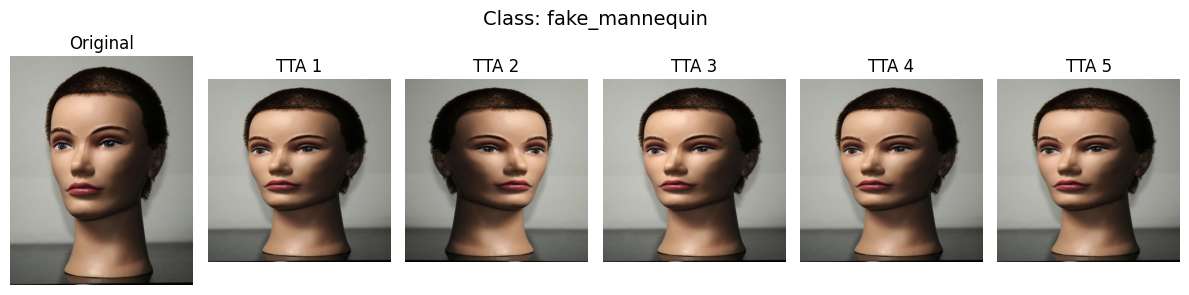


Visualizing class: fake_mask


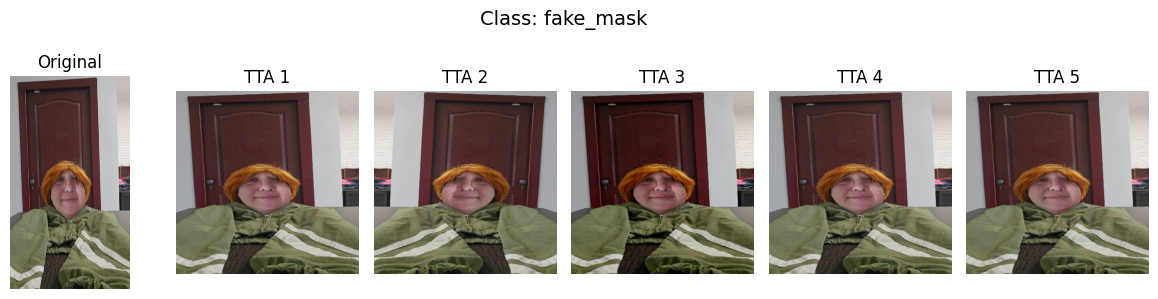


Visualizing class: fake_printed


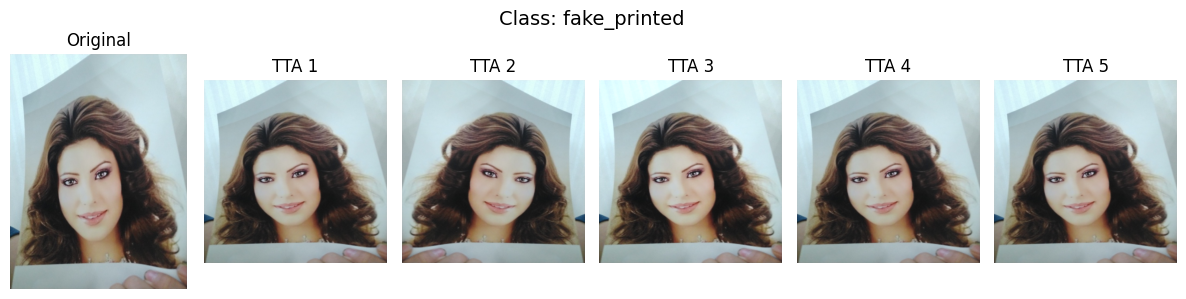


Visualizing class: fake_screen


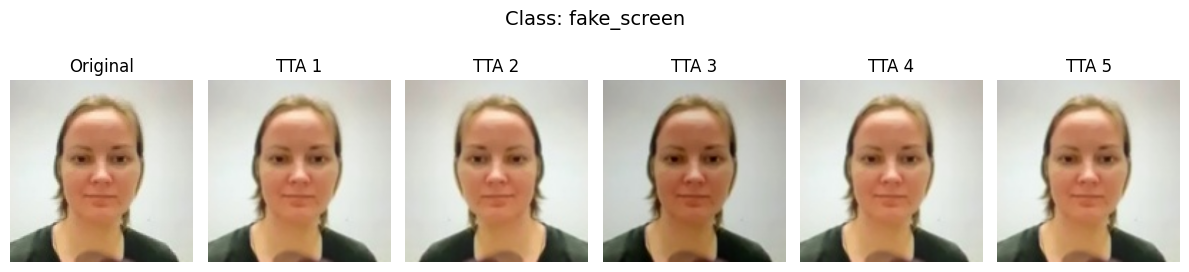


Visualizing class: fake_unknown


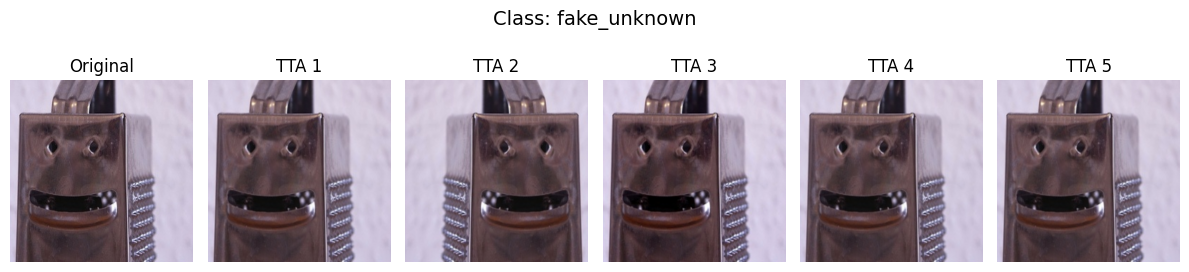


Visualizing class: realperson


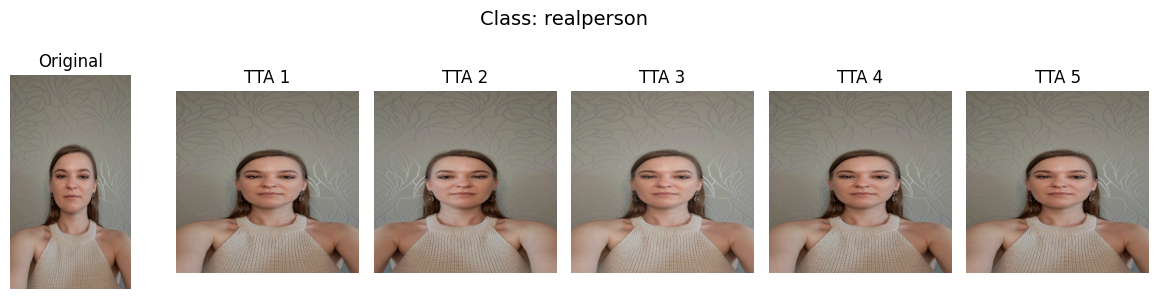

In [22]:
train_tfms = A.Compose([
    A.Resize(384, 384),
    A.HorizontalFlip(p=0.5),
    A.CenterCrop(128, 128, p=0.3),
    A.Resize(384, 384),
])

tta_tfms = [
    A.Compose([A.Resize(384, 384)]),
    A.Compose([
        A.Resize(384, 384),
        A.HorizontalFlip(p=1.0),
    ]),
    A.Compose([
        A.Resize(384, 384),
        A.RandomBrightnessContrast(
            brightness_limit=0.1,
            contrast_limit=0.1,
            p=1.0
        ),
    ]),
    A.Compose([
        A.Resize(384, 384),
    ]),
]

test_tfms = A.Compose([
    A.Resize(384, 384)
])

no_aug_tfms = A.Compose([
    A.Resize(384, 384)
])

# ===== VISUALIZATION PER CLASS =====
num_aug = 5  # number of augmented samples per class

for label in classes:
    print(f"\nVisualizing class: {label}")

    class_df = df[df["label"] == label2id[label]]
    
    if len(class_df) == 0:
        print(f"⚠️ No samples found for {label}")
        continue

    sample_row = class_df.iloc[0]
    img_path = sample_row["path"]

    image = cv2.imread(img_path)
    
    if image is None:
        print(f"⚠️ Failed to read image: {img_path}")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 3))
    plt.suptitle(f"Class: {label}", fontsize=14)

    # original
    plt.subplot(1, num_aug + 1, 1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis("off")

    # augmented versions
    for i in range(num_aug):
        tta = tta_tfms[i % len(tta_tfms)]
        aug = tta(image=image)["image"]
    
        plt.subplot(1, num_aug + 1, i + 2)
        plt.imshow(aug)
        plt.title(f"TTA {i+1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Custom Dataset, Training Setup, dan Validation

Pada bagian ini diimplementasikan dataset custom serta fungsi training dan evaluasi model.

---

### 🔹 Custom Dataset (FaceDataset)

Kelas `FaceDataset` digunakan untuk memuat data citra secara dinamis dari DataFrame.

Fitur utama:
- Membaca gambar menggunakan OpenCV dan mengubah ke format RGB
- Menangani error jika gambar gagal dibaca (fail-safe)
- Menerapkan **augmentasi secara kondisional**:
  - Kelas `fake_screen` → menggunakan transformasi khusus tanpa augmentasi tambahan
  - Kelas lain → menggunakan augmentasi training

- Normalisasi citra menggunakan standar ImageNet:
  - Mean: `[0.485, 0.456, 0.406]`
  - Std: `[0.229, 0.224, 0.225]`

- Mengubah format citra menjadi `(C, H, W)` untuk PyTorch

Pendekatan ini memungkinkan preprocessing yang fleksibel sesuai karakteristik tiap kelas.

---

### 🔹 Stratified K-Fold

Digunakan `StratifiedKFold` untuk:
- Membagi dataset menjadi beberapa fold
- Menjaga distribusi kelas tetap seimbang
- Mengurangi bias pada proses training dan evaluasi

---

### 🔹 Training Function

Fungsi `train_one_epoch()` digunakan untuk:
- Melatih model selama satu epoch
- Menghitung:
  - Loss
  - Accuracy

Langkah utama:
1. Forward pass
2. Hitung loss
3. Backpropagation
4. Update parameter model

---

### 🔹 Validation Function

Fungsi `validate()` digunakan untuk mengevaluasi performa model pada data validasi.

Metrik yang digunakan:
- **Accuracy**
- **F1-score (macro)**

F1-score dipilih karena:
> Lebih representatif untuk dataset dengan distribusi kelas tidak seimbang

---

### 🔹 Insight

Struktur ini memungkinkan:
- Pipeline training yang modular dan fleksibel
- Evaluasi yang lebih adil melalui K-Fold
- Penanganan dataset kompleks dengan augmentasi adaptif

Pendekatan ini penting untuk meningkatkan kemampuan generalisasi model pada data dengan variasi tinggi.

In [23]:
class FaceDataset(Dataset):
    def __init__(self, df, transforms=None, no_aug_transforms=None, fake_screen_label=None):
        self.df = df.reset_index(drop=True)
        self.transforms = transforms
        self.no_aug_transforms = no_aug_transforms
        self.fake_screen_label = fake_screen_label

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img = cv2.imread(row.path)
        
        # 🔥 IMPORTANT: prevent crash if image fails to load
        if img is None:
            raise ValueError(f"Failed to read image: {row.path}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        label = row.label

        # 🔥 conditional transform
        if label == self.fake_screen_label:
            if self.no_aug_transforms:
                img = self.no_aug_transforms(image=img)["image"]
        else:
            if self.transforms:
                img = self.transforms(image=img)["image"]

        img = img.astype(np.float32) / 255.0

        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = (img - mean) / std

        img = np.transpose(img, (2,0,1))

        return torch.tensor(img, dtype=torch.float32), torch.tensor(label)

## Vision Transformer Training (K-Fold)

Pada tahap ini dilakukan pelatihan model **Vision Transformer (ViT)** menggunakan pendekatan **Stratified K-Fold Cross Validation** untuk meningkatkan robustness dan generalisasi model.

---

### 🔹 K-Fold Strategy

Dataset dibagi menjadi beberapa fold menggunakan `StratifiedKFold`:
- Distribusi kelas tetap seimbang pada setiap fold
- Setiap fold digunakan sebagai validation secara bergantian
- Menghasilkan beberapa model untuk tahap ensemble

---

### 🔹 Data Loading

Untuk setiap fold:
- **Training data** menggunakan augmentasi (`train_tfms`)
- **Validation data** hanya menggunakan transformasi dasar (`test_tfms`)

Data dimuat menggunakan `DataLoader` dengan:
- Batch size: 32  
- Shuffle: hanya untuk training  
- `num_workers = 0` → menjaga stabilitas pada environment tertentu (misalnya Kaggle)  
- `seed_worker` + `generator` → memastikan reproducibility  

---

### 🔹 Model

Model yang digunakan:
- **Vision Transformer (vit_base_patch16_384)**
- Pretrained pada dataset besar
- Fine-tuned untuk 6 kelas

Keunggulan ViT:
- Mampu menangkap **hubungan global antar patch**
- Efektif untuk memahami struktur visual kompleks

---

### 🔹 Training Configuration

- **Loss Function**: CrossEntropyLoss  
- **Optimizer**: AdamW  
- **Learning Rate**: 3e-5  
- **Weight Decay**: 1e-4  
- **Epoch**: 2 (eksperimen awal)

Learning rate kecil digunakan untuk:
> Menjaga stabilitas fine-tuning pada model pretrained

---

### 🔹 Training Process

Untuk setiap epoch:
1. Model dilatih menggunakan data training  
2. Dilakukan evaluasi pada data validation  
3. Menghitung:
   - Training Accuracy  
   - Validation F1-score  

---

### 🔹 Model Selection

Model terbaik dipilih berdasarkan:
- **F1-score tertinggi pada validation set**

Jika performa meningkat:
- Model disimpan dalam format `.pth`
- Digunakan pada tahap inference dan ensemble

---

### 🔹 Insight

Pendekatan ini memungkinkan:
- Mengurangi bias akibat pembagian data
- Meningkatkan stabilitas hasil
- Menghasilkan beberapa model dengan karakteristik berbeda

Sehingga:
> Lebih efektif saat dikombinasikan dengan TTA dan ensemble pada tahap inference

In [24]:
skf = StratifiedKFold(n_splits=7, shuffle=True, random_state=42)

from sklearn.metrics import f1_score

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for imgs, labels in tqdm(loader):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(imgs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), correct / total


def validate(model, loader):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)

            outputs = model(imgs)
            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    acc = (all_preds == all_labels).mean()
    f1 = f1_score(all_labels, all_preds, average="macro")

    return acc, f1

In [25]:
EPOCHS = 12
fold_models = []

SAVE_PATH = SAVE_DIR
os.makedirs(SAVE_PATH, exist_ok=True)

for fold, (train_idx, val_idx) in enumerate(skf.split(df, df["label"])):

    print(f"\n========== FOLD {fold+1} ==========")

    train_df = df.iloc[train_idx]
    val_df = df.iloc[val_idx]

    train_dataset = FaceDataset(train_df, train_tfms)
    val_dataset = FaceDataset(val_df, test_tfms)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=0,  # 🔥 IMPORTANT FIX (was 2)
        worker_init_fn=seed_worker,
        generator=g
    )
    
    val_loader = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0,  # 🔥 IMPORTANT FIX
        worker_init_fn=seed_worker,
        generator=g
    )

    model = timm.create_model(
        "vit_base_patch16_384",
        pretrained=True,
        num_classes=6
    )

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)

    best_f1 = 0

    for epoch in range(EPOCHS):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, val_f1 = validate(model, val_loader)

        print(f"Epoch {epoch+1} | Train Acc: {train_acc:.4f} | Val F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1

            model_path = os.path.join(SAVE_PATH, f"model_fold_{fold}.pth")
            torch.save(model.state_dict(), model_path)

            fold_models.append(model_path)


========== FOLD 1 ==========


model.safetensors:   0%|          | 0.00/347M [00:00<?, ?B/s]

100%|██████████| 48/48 [04:01<00:00,  5.04s/it]


Epoch 1 | Train Acc: 0.7966 | Val F1: 0.9181


100%|██████████| 48/48 [03:51<00:00,  4.82s/it]


Epoch 2 | Train Acc: 0.9539 | Val F1: 0.9795


... (160 outputs left out)

100%|██████████| 48/48 [03:40<00:00,  4.60s/it]


Epoch 11 | Train Acc: 0.9974 | Val F1: 0.9653


100%|██████████| 48/48 [03:40<00:00,  4.59s/it]


Epoch 12 | Train Acc: 0.9888 | Val F1: 0.9022


## Inference, TTA, dan Ensemble (ViT)

Pada tahap ini dilakukan proses inferensi menggunakan model Vision Transformer (ViT) yang telah dilatih dengan pendekatan K-Fold, serta dikombinasikan dengan Test-Time Augmentation (TTA) dan ensemble.

---

### 🔹 Persiapan Data Test

Data test diambil dari file submission (`id`) dan dicocokkan dengan file gambar yang tersedia (`.jpg`, `.png`, `.jpeg`).

Proses ini memastikan:
- Semua file gambar valid ditemukan
- Dataset siap digunakan untuk inference

Output:
- DataFrame `test_df` berisi path gambar test

---

### 🔹 Test Dataset

Kelas `TestDataset` digunakan untuk:
- Membaca gambar dari path
- Mengubah format ke RGB
- Menerapkan transformasi (resize)
- Normalisasi menggunakan standar ImageNet

Tambahan penting:
- **Error handling** → mencegah crash jika gambar gagal dibaca

---

### 🔹 DataLoader

Data dimuat menggunakan:
- Batch size: 32
- Shuffle: False (menjaga urutan)
- `num_workers = 0` → menghindari freeze di environment tertentu

---

### 🔹 Load Model per Fold

Semua model hasil K-Fold:
- Di-load dari file `.pth`
- Diurutkan berdasarkan index fold
- Digunakan untuk inference secara independen

---

### 🔹 Test-Time Augmentation (TTA)

Untuk setiap batch:
1. Gambar di-*denormalize*
2. Diberikan berbagai transformasi:
   - Resize
   - Horizontal Flip
   - Brightness & Contrast
3. Dihasilkan beberapa versi citra

Setiap versi:
- Diproses oleh model
- Menghasilkan probabilitas prediksi

---

### 🔹 Aggregasi TTA

Hasil dari berbagai augmentasi digabungkan menggunakan:
- **Averaging probabilitas (mean)**

Tujuan:
- Mengurangi noise
- Meningkatkan stabilitas prediksi
- Menghasilkan output yang lebih robust

---

### 🔹 Ensemble Antar Fold

Setelah TTA:
- Setiap fold menghasilkan prediksi

Kemudian:
1. Probabilitas dari semua fold dikumpulkan
2. Dilakukan averaging antar fold
3. Dipilih kelas dengan probabilitas tertinggi (`argmax`)

---

### 🔹 Output Final

Hasil akhir:
- Label prediksi (`label_pred`)
- Probabilitas untuk setiap kelas
- Disimpan dalam file `.csv`


In [26]:
submission_df = pd.read_csv(SUBMISSION_PATH)

test_paths = []
for img_id in submission_df["id"]:
    for ext in [".jpg", ".png", ".jpeg"]:
        path = os.path.join(TEST_PATH, img_id + ext)
        if os.path.exists(path):
            test_paths.append(path)
            break

test_df = pd.DataFrame({"path": test_paths})

print("Total test samples found:", len(test_df))  # 🔥 debug


class TestDataset(Dataset):
    def __init__(self, df, transforms=None):
        self.df = df
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = self.df.iloc[idx].path
        img = cv2.imread(path)

        # 🔥 IMPORTANT: prevent crash
        if img is None:
            raise ValueError(f"Failed to read image: {path}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transforms:
            img = self.transforms(image=img)["image"]

        img = img.astype(np.float32) / 255.0

        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img = (img - mean) / std

        img = np.transpose(img, (2,0,1))

        return torch.tensor(img, dtype=torch.float32)

Total test samples found: 404


In [27]:
test_dataset = TestDataset(test_df, test_tfms)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0  # 🔥 FIX FREEZE
)

all_fold_preds = []

print("===== DEBUG START =====")

model_dir = f"{SAVE_DIR}"

model_files = [
    f for f in os.listdir(model_dir)
    if f.endswith(".pth") and f.startswith("model_fold_")
]

model_files = sorted(
    model_files,
    key=lambda x: int(x.split("_")[-1].split(".")[0])
)

print("Models:", model_files)
print("Total:", len(model_files))


for fold_idx, model_name in enumerate(model_files):

    fold_path = os.path.join(model_dir, model_name)

    print(f"Running inference for Fold {fold_idx}")

    model = timm.create_model(
        "vit_base_patch16_384",
        pretrained=False,
        num_classes=6
    )

    model.load_state_dict(torch.load(fold_path, map_location=device))

    model = model.to(device)
    model.eval()

    fold_preds = []

    with torch.no_grad():
        for imgs in test_loader:

            imgs = imgs.to(device)
            tta_preds = []

            for tta in tta_tfms:
                aug_imgs = []

                for img in imgs.cpu().numpy():
                    img = np.transpose(img, (1,2,0))

                    mean = np.array([0.485, 0.456, 0.406])
                    std = np.array([0.229, 0.224, 0.225])
                    img = (img * std) + mean
                    img = (img * 255).astype(np.uint8)

                    aug = tta(image=img)["image"]

                    aug = aug.astype(np.float32) / 255.0
                    aug = (aug - mean) / std
                    aug = np.transpose(aug, (2,0,1))

                    aug_imgs.append(aug)

                aug_imgs = torch.from_numpy(np.stack(aug_imgs)).float().to(device)

                outputs = model(aug_imgs)
                probs = torch.softmax(outputs, dim=1)

                tta_preds.append(probs)

            tta_preds = torch.stack(tta_preds).mean(0)

            fold_preds.append(tta_preds.cpu().numpy())

    fold_probs = np.concatenate(fold_preds)
    all_fold_preds.append(fold_probs)

    fold_labels = np.argmax(fold_probs, axis=1)

    fold_df = submission_df.copy()
    fold_df["label"] = [id2label[p] for p in fold_labels]

    fold_df.to_csv(
        os.path.join(model_dir, f"submission_fold_{fold_idx}.csv"),
        index=False
    )

    print(f"Saved submission_fold_{fold_idx}.csv")


# ===== FINAL ENSEMBLE =====

all_fold_preds = np.array(all_fold_preds)

final_probs = np.mean(all_fold_preds, axis=0)
final_preds = np.argmax(final_probs, axis=1)

prob_df = submission_df.copy()
prob_df["label_pred"] = [id2label[p] for p in final_preds]

for i, cls in enumerate(classes):
    prob_df[cls] = final_probs[:, i]

prob_df["confidence"] = prob_df[classes].max(axis=1)

def top2_gap(row):
    sorted_probs = np.sort(row[classes].values)
    return sorted_probs[-1] - sorted_probs[-2]

prob_df["margin"] = prob_df.apply(top2_gap, axis=1)

prob_df.to_csv(os.path.join(model_dir, "full_analysis.csv"), index=False)

print("Saved: full_analysis.csv 🚀")

hard_samples = prob_df[
    (prob_df["confidence"] < 0.6)
].sort_values("confidence")


===== DEBUG START =====
Models: ['model_fold_0.pth', 'model_fold_1.pth', 'model_fold_2.pth', 'model_fold_3.pth', 'model_fold_4.pth', 'model_fold_5.pth', 'model_fold_6.pth']
Total: 7
Running inference for Fold 0
Saved submission_fold_0.csv
Running inference for Fold 1
Saved submission_fold_1.csv
Running inference for Fold 2
Saved submission_fold_2.csv
Running inference for Fold 3
Saved submission_fold_3.csv
Running inference for Fold 4
Saved submission_fold_4.csv
Running inference for Fold 5
Saved submission_fold_5.csv
Running inference for Fold 6
Saved submission_fold_6.csv
Saved: full_analysis.csv 🚀


# Ensemble Setup (ConvNeXt + Vision Transformer)

Pada tahap ini dilakukan persiapan untuk menggabungkan dua model berbeda:
- **ConvNeXt (CNN-based)**
- **Vision Transformer (ViT)**

Pendekatan ini bertujuan untuk memanfaatkan keunggulan masing-masing arsitektur dalam satu sistem prediksi.

---

### 🔹 Class & Label Mapping

Didefinisikan enam kelas utama:
- `fake_mannequin`
- `fake_mask`
- `fake_printed`
- `fake_screen`
- `fake_unknown`
- `realperson`

Digunakan dua mapping:
- `label2id` → label → angka  
- `id2label` → angka → label  

---

### 🔹 Confidence Mapping (CSV)

Mapping tambahan digunakan untuk menyimpan probabilitas setiap kelas dalam format submission:

Contoh:
- `fake_mask` → `conf_mask`
- `realperson` → `conf_real`

Hal ini memungkinkan analisis probabilitas per kelas pada hasil akhir.

---

### 🔹 Environment Setup

Konfigurasi utama:
- Device: GPU (CUDA) jika tersedia
- Base directory: `/kaggle/working/`
- Path model:
  - ConvNeXt → `models_conv`
  - ViT → `models_VIT`

---

### 🔹 Transform per Model

Karena kedua model memiliki kebutuhan input berbeda, digunakan transformasi terpisah:

#### 📌 ConvNeXt
- Resize: **256×256**
- Normalisasi: ImageNet

#### 📌 Vision Transformer (ViT)
- Resize: **384×384**
- Normalisasi: ImageNet

Perbedaan ini penting karena:
> CNN lebih fokus pada detail lokal, sedangkan ViT membutuhkan resolusi lebih tinggi untuk memahami konteks global

---

### 🔹 Tujuan Ensemble

Pendekatan ensemble dilakukan untuk:
- Menggabungkan keunggulan CNN (fitur lokal)
- Menggabungkan keunggulan Transformer (fitur global)
- Mengurangi variansi prediksi
- Meningkatkan stabilitas hasil

---

### 🔹 Strategi Ensemble

Metode yang digunakan:
- **Hard Voting**

Konsep:
- Setiap model memberikan prediksi kelas
- Kelas dengan jumlah voting terbanyak dipilih sebagai output akhir


In [28]:
classes = [
    "fake_mannequin",
    "fake_mask",
    "fake_printed",
    "fake_screen",
    "fake_unknown",
    "realperson"
]

label2id = {c:i for i,c in enumerate(classes)}
id2label = {i:c for c,i in label2id.items()}

csv_mapping = {
    "fake_mask": "conf_mask",
    "realperson": "conf_real",
    "fake_printed": "conf_printed",
    "fake_unknown": "conf_unknown",
    "fake_mannequin": "conf_mannequin",
}

In [29]:
# =========================
# CONFIG
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BASE_PATH = "/kaggle/working/"  

TEST_PATH   = "/kaggle/input/datasets/nasywak/dataset/ensemble1_dataset/test"
SAMPLE_PATH ="/kaggle/input/datasets/nasywak/sample-sub/samplesubmission.csv"

CONV_PATH   = os.path.join(BASE_PATH,"models/models_conv")
VIT_PATH    = os.path.join(BASE_PATH,"models/models_VIT")

In [30]:
# =========================
# TRANSFORM
# =========================
transform_conv = A.Compose([
    A.Resize(256, 256),
    A.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    ToTensorV2()
])

transform_vit = A.Compose([
    A.Resize(384, 384),
    A.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    ToTensorV2()
])

## Multi-Model Dataset & Model Loading

Pada tahap ini disiapkan komponen utama untuk inference ensemble, yaitu:
- Dataset yang mendukung dua model sekaligus (ConvNeXt & ViT)
- Fungsi loading model secara fleksibel dari hasil training

---

### 🔹 Test Dataset (Multi-Input)

Kelas `TestDataset` dirancang untuk mendukung **dua jenis input sekaligus**:
- Input untuk **ConvNeXt (256×256)**
- Input untuk **ViT (384×384)**

Proses yang dilakukan:
1. Membaca file submission (`id`)
2. Mencari file gambar dengan berbagai ekstensi (`.jpg`, `.png`, `.jpeg`)
3. Memastikan gambar ditemukan (fail-safe)
4. Membaca gambar dan mengubah ke RGB
5. Menghasilkan dua versi citra:
   - `img_conv` → untuk ConvNeXt
   - `img_vit` → untuk ViT

Output:
- `(img_conv, img_vit, img_id)`

Pendekatan ini memungkinkan:
> Satu dataset digunakan untuk dua model dengan kebutuhan input berbeda

---

### 🔹 Model Loading Function

Fungsi `load_models()` digunakan untuk:
- Memuat seluruh model dari folder tertentu (`.pth`)
- Mendukung berbagai arsitektur (ConvNeXt / ViT)
- Menghandle variasi format checkpoint

---

### 🔹 Fitur Penting

#### 📌 Dynamic Model Initialization
- Model dibuat ulang sesuai arsitektur
- Mendukung parameter tambahan seperti `img_size` (untuk ViT)

---

#### 📌 Flexible Checkpoint Handling
Checkpoint dapat memiliki berbagai format:
- `state_dict`
- `model`

Fungsi ini secara otomatis menyesuaikan struktur checkpoint.

---

#### 📌 Prefix Cleaning
Menghapus prefix `"module."` yang biasanya muncul saat training menggunakan multi-GPU.

---

#### 📌 Evaluation Mode
Setiap model:
- Dipindahkan ke device (GPU/CPU)
- Di-set ke mode evaluasi (`eval()`)

---

### 🔹 Tujuan Pendekatan

Struktur ini dirancang untuk:
- Mendukung inference multi-model secara efisien
- Menghindari duplikasi dataset
- Mempermudah integrasi ensemble

---

### 🔹 Insight

Pendekatan ini memungkinkan:
- Kombinasi model dengan arsitektur berbeda
- Penggunaan preprocessing yang sesuai untuk masing-masing model
- Pipeline inference yang scalable dan modular

Sehingga:
> Sistem dapat dengan mudah diperluas dengan model tambahan di masa depan

In [31]:
class TestDataset(Dataset):
    def __init__(self, csv_path, img_dir):
        self.df = pd.read_csv(csv_path)
        self.img_dir = img_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_id = str(row["id"])

        path = None
        for ext in [".jpg", ".png", ".jpeg"]:
            p = os.path.join(self.img_dir, img_id + ext)
            if os.path.exists(p):
                path = p
                break

        if path is None:
            raise ValueError(f"Image not found: {img_id}")

        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        img_conv = transform_conv(image=image)["image"]
        img_vit  = transform_vit(image=image)["image"]

        return img_conv, img_vit, img_id

In [32]:
def load_models(folder, arch, img_size=None):
    models = []
    files = sorted(glob.glob(os.path.join(folder, "*.pth")))

    for f in files:
        checkpoint = torch.load(f, map_location="cpu")

        if img_size:
            model = timm.create_model(
                arch,
                pretrained=False,
                num_classes=len(classes),
                img_size=img_size
            )
        else:
            model = timm.create_model(
                arch,
                pretrained=False,
                num_classes=len(classes)
            )

        if isinstance(checkpoint, dict):
            if "state_dict" in checkpoint:
                checkpoint = checkpoint["state_dict"]
            elif "model" in checkpoint:
                checkpoint = checkpoint["model"]

        # fix prefix module.
        new_state_dict = {}
        for k, v in checkpoint.items():
            new_key = k.replace("module.", "")
            new_state_dict[new_key] = v

        model.load_state_dict(new_state_dict, strict=False)

        model = model.to(device)
        model.eval()

        models.append(model)

    return models

## Ensemble Hard Voting dengan Adaptive Refinement

Pada tahap ini dilakukan penggabungan prediksi dari dua model berbeda:
- **ConvNeXt**
- **Vision Transformer (ViT)**

Pendekatan yang digunakan adalah **hard voting yang diperkaya dengan penyesuaian adaptif berbasis distribusi probabilitas**, sehingga mampu menghasilkan prediksi yang lebih stabil dan robust.

---

### 🔹 1. Forward Prediction

Untuk setiap model:
- Dilakukan forward pass
- Menghasilkan probabilitas menggunakan **softmax**

Output:
- Probabilitas prediksi dari model ConvNeXt
- Probabilitas prediksi dari model ViT

---

### 🔹 2. Aggregasi Probabilitas

Semua probabilitas digabungkan:
- Di-*stack* menjadi satu tensor
- Diambil rata-rata (**mean probability**)

Tujuan:
- Menghasilkan estimasi probabilitas global
- Mengurangi variansi dari model individual

---

### 🔹 3. Hard Voting (Majority Vote)

Dilakukan voting berbasis label:
- Setiap model memberikan prediksi kelas
- Dipilih kelas dengan frekuensi terbanyak (mode)

Selain itu:
- Dilakukan agregasi terpisah untuk masing-masing model:
  - ConvNeXt (`conv_final`)
  - ViT (`vit_final`)

Hal ini memungkinkan analisis konsistensi antar model.

---

### 🔹 4. Konsistensi dan Kekuatan Prediksi

Selain jumlah voting, diperhatikan juga:
- Tingkat kesepakatan antar model
- Dominansi prediksi pada kelas tertentu

Informasi ini digunakan untuk menangani kasus dengan potensi ambiguitas tinggi.

---

### 🔹 5. Adaptive Adjustment berbasis Probabilitas

Selain mekanisme voting, dilakukan penyesuaian prediksi secara adaptif dengan mempertimbangkan perilaku distribusi probabilitas model.

Pendekatan ini memanfaatkan beberapa sinyal penting:
- Konsistensi prediksi antar model  
- Distribusi probabilitas yang dihasilkan  
- Perbedaan tingkat keyakinan antar kelas  
- Kedekatan nilai probabilitas pada kelas-kelas teratas  

Melalui kombinasi informasi tersebut, sistem dapat:
- Mengidentifikasi kondisi dengan tingkat ambiguitas tinggi  
- Menangani kasus dengan perbedaan probabilitas yang tipis (*low confidence gap*)  
- Menyesuaikan prediksi pada situasi borderline secara lebih stabil  

Pendekatan ini membantu:
- Mengurangi kesalahan pada kelas dengan kemiripan visual tinggi  
- Mengatasi overlap antar kelas  
- Meningkatkan sensitivitas terhadap perbedaan fitur yang halus  
- Menghasilkan prediksi yang lebih konsisten dan robust  

---

### 🔹 6. Top-2 Prediction

Mengambil:
- 2 probabilitas tertinggi (`top2_probs`)
- Indeks kelasnya (`top2_idx`)

Digunakan untuk:
- Analisis tingkat keyakinan
- Identifikasi kasus ambigu
- Evaluasi perilaku model pada prediksi borderline

---

### 🔹 Insight Pendekatan

Metode ini menggabungkan:

- **Hard voting** → keputusan berbasis mayoritas  
- **Probabilistic aggregation** → distribusi prediksi  
- **Adaptive refinement** → penyesuaian berbasis pola  

Sehingga:
> Sistem tidak hanya bergantung pada satu sumber keputusan, tetapi mengintegrasikan berbagai sinyal prediksi untuk meningkatkan stabilitas dan kualitas hasil.

---


In [33]:
def ensemble_hardvoting(
    conv_models, vit_models, 
    img_conv, img_vit,
    unknown_idx, printed_idx, screen_idx, mask_idx, real_idx
):
    conv_preds_list = []
    vit_preds_list = []

    # =====================
    # FORWARD
    # =====================
    for m in conv_models:
        logits = m(img_conv)
        probs = torch.softmax(logits, dim=1)
        conv_preds_list.append(probs.detach().cpu())

    for m in vit_models:
        logits = m(img_vit)
        probs = torch.softmax(logits, dim=1)
        vit_preds_list.append(probs.detach().cpu())

    # =====================
    # PROB AGGREGATION
    # =====================
    all_preds = conv_preds_list + vit_preds_list
    stacked_probs = torch.stack(all_preds, dim=0)
    mean_probs = stacked_probs.mean(dim=0)

    # =====================
    # LABEL FOR RULE
    # =====================
    stacked_labels = torch.stack(
        [p.argmax(dim=1) for p in all_preds], dim=1
    )
    final_preds, _ = torch.mode(stacked_labels, dim=1)

    conv_stack = torch.stack([p.argmax(dim=1) for p in conv_preds_list], dim=1)
    vit_stack = torch.stack([p.argmax(dim=1) for p in vit_preds_list], dim=1)

    conv_final, _ = torch.mode(conv_stack, dim=1)
    vit_final, _ = torch.mode(vit_stack, dim=1)

    # =====================
    # VOTE STRENGTH
    # =====================
    mask_votes = (stacked_labels == mask_idx).sum(dim=1)
    printed_votes = (stacked_labels == printed_idx).sum(dim=1)

    # =====================
    # RULE
    # =====================
    mask_rule = (conv_final == mask_idx) | (vit_final == mask_idx)
    final_preds[mask_rule] = conv_final[mask_rule]

    printed_rule = (
        ((conv_final == printed_idx) | (vit_final == printed_idx))
        & ~((conv_final == mask_idx) & (mask_votes > printed_votes))
    )
    final_preds[printed_rule] = vit_final[printed_rule]

    screen_rule = (conv_final == screen_idx) | (vit_final == screen_idx)
    final_preds[screen_rule] = vit_final[screen_rule]

    conflict_1 = (vit_final == printed_idx) & (conv_final == screen_idx)
    final_preds[conflict_1] = conv_final[conflict_1]

    conflict_2 = (vit_final == real_idx) & (conv_final == printed_idx)
    final_preds[conflict_2] = conv_final[conflict_2]

    # =====================
    # FINAL CUSTOM RULE
    # =====================
    conf_printed_vals = mean_probs[:, printed_idx]
    conf_mask_vals = mean_probs[:, mask_idx]
    diff = conf_printed_vals - conf_mask_vals

    mask_override = (diff >= 0.105) & (diff <= 0.115)
    final_preds[mask_override] = mask_idx

    # =====================
    # FINAL CUSTOM RULE (MANNEQUIN → UNKNOWN)
    # =====================
    conf_mannequin_vals = mean_probs[:, label2id["fake_mannequin"]]
    conf_unknown_vals   = mean_probs[:, unknown_idx]

    diff_mu = conf_mannequin_vals - conf_unknown_vals

    unknown_override = (diff_mu >= 0.15) & (diff_mu <= 0.30)
    final_preds[unknown_override] = unknown_idx

    # =====================
    # TOP2
    # =====================
    top2_probs, top2_idx = torch.topk(mean_probs, k=2, dim=1)

    return final_preds, mean_probs, top2_idx, top2_probs

## Ensemble Inference Execution

Pada tahap ini dilakukan proses inferensi akhir dengan menggabungkan model ConvNeXt dan Vision Transformer menggunakan pendekatan ensemble.

---

### 🔹 Dataset & DataLoader

Dataset test dimuat menggunakan `TestDataset`, yang menghasilkan:
- Input untuk ConvNeXt (`img_conv`)
- Input untuk ViT (`img_vit`)
- ID gambar (`img_id`)

Data kemudian diproses menggunakan `DataLoader` dengan:
- Batch size kecil (4) untuk menjaga stabilitas memori
- Tanpa shuffle untuk mempertahankan urutan data

---

### 🔹 Inisialisasi Storage

Beberapa variabel disiapkan untuk menyimpan hasil:
- `all_preds` → prediksi akhir
- `all_ids` → ID gambar
- `all_probs` → probabilitas setiap kelas
- `top2_idx`, `top2_probs` → dua prediksi teratas

Selain itu, disiapkan indeks label untuk kelas-kelas penting seperti:
- `fake_unknown`
- `fake_screen`
- `fake_printed`
- `fake_mask`
- `realperson`

---

### 🔹 Load Model

Model dari kedua arsitektur dimuat:
- **ConvNeXt** → dari `models_conv`
- **ViT** → dari `models_VIT`

Setiap model:
- Di-load dari file `.pth`
- Di-set ke mode evaluasi

---

### 🔹 Proses Inference

Untuk setiap batch:
1. Data dipindahkan ke device (GPU/CPU)
2. Dilakukan inference menggunakan fungsi:
   - `ensemble_hardvoting()`

Fungsi ini menghasilkan:
- Prediksi akhir
- Probabilitas rata-rata
- Top-2 prediksi dan probabilitasnya

---

### 🔹 Penyimpanan Hasil

Untuk setiap batch:
- Prediksi disimpan ke `all_preds`
- ID gambar disimpan ke `all_ids`
- Probabilitas disimpan untuk analisis lanjutan
- Top-2 prediksi disimpan untuk evaluasi ambiguitas

---

### 🔹 Memory Optimization

Setelah setiap batch:
- Tensor input dihapus (`del`)
- Cache GPU dibersihkan (`torch.cuda.empty_cache()`)

Hal ini penting untuk:
- Menghindari out-of-memory
- Menjaga stabilitas inference pada dataset besar

---

### 🔹 Aggregasi Hasil

Setelah seluruh batch selesai:
- Probabilitas digabung (`torch.cat`)
- Top-2 hasil juga digabung

Hasil akhir:
- Prediksi lengkap untuk seluruh dataset
- Informasi probabilitas untuk setiap sampel

---


In [34]:
# =========================
# DATASET + LOADER
# =========================
dataset = TestDataset(SAMPLE_PATH, TEST_PATH)

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

# =========================
# INIT STORAGE
# =========================
all_preds = []
all_ids = []

all_probs = []
all_top2_idx = []
all_top2_probs = []

UNKNOWN_CLASS = "fake_unknown"   
SCREEN_CLASS  = "fake_screen"
PRINTED_CLASS = "fake_printed" 
MASK_CLASS    = "fake_mask"
REAL_CLASS    = "realperson"

real_idx = label2id[REAL_CLASS]
unknown_idx = label2id[UNKNOWN_CLASS]
screen_idx  = label2id[SCREEN_CLASS]
printed_idx = label2id[PRINTED_CLASS]
mask_idx    = label2id[MASK_CLASS]

# =========================
# LOAD MODELS
# =========================
conv_models = load_models(CONV_PATH, "convnext_small.fb_in22k_ft_in1k")
vit_models  = load_models(VIT_PATH,  "vit_base_patch16_384", img_size=384)

# =========================
# INFERENCE
# =========================
with torch.inference_mode():
    for img_conv, img_vit, ids in tqdm(loader):

        img_conv = img_conv.to(device)
        img_vit  = img_vit.to(device)

        preds, probs, top2_idx, top2_probs = ensemble_hardvoting(
            conv_models,
            vit_models,
            img_conv,
            img_vit,
            unknown_idx=unknown_idx,
            printed_idx=printed_idx, 
            screen_idx=screen_idx,
            mask_idx=mask_idx,
            real_idx=real_idx
        )

        all_preds.extend(preds.numpy())
        all_ids.extend(ids)

        all_probs.append(probs.cpu())
        all_top2_idx.append(top2_idx.cpu())
        all_top2_probs.append(top2_probs.cpu())

        del img_conv, img_vit
        torch.cuda.empty_cache()

# =========================
# CONCAT
# =========================
all_probs = torch.cat(all_probs, dim=0)
all_top2_idx = torch.cat(all_top2_idx, dim=0)
all_top2_probs = torch.cat(all_top2_probs, dim=0)

100%|██████████| 101/101 [02:51<00:00,  1.69s/it]


## Final Output, Confidence Extraction, dan Submission

Pada tahap akhir ini dilakukan proses pengolahan hasil prediksi menjadi format yang siap digunakan untuk submission serta analisis lebih lanjut.

---

### 🔹 Aggregasi Tensor (Safe Concatenation)

Hasil prediksi dari setiap batch dikumpulkan dalam bentuk list, kemudian digabungkan menjadi satu tensor menggunakan `torch.cat`.

Pendekatan ini memastikan:
- Konsistensi bentuk data
- Menghindari error jika data masih dalam bentuk list

---

### 🔹 Penyusunan Output per Sample

Untuk setiap data:
- Diambil probabilitas prediksi (`probs`)
- Dibentuk satu baris data (`row`) yang berisi:

#### - Informasi Utama
- `id` → ID gambar
- `label` → hasil prediksi akhir

---

#### - Confidence per Class
Probabilitas untuk kelas-kelas penting:
- `conf_mask`
- `conf_real`
- `conf_printed`
- `conf_unknown`
- `conf_mannequin`

Digunakan untuk:
- Analisis performa model
- Interpretasi hasil prediksi

---

#### - Top-2 Prediction
Informasi dua prediksi teratas:
- `highest_conf` → probabilitas tertinggi
- `second_highest_conf` → probabilitas kedua
- `highest_label` → label prediksi utama
- `second_label` → label alternatif

Tujuan:
- Mengidentifikasi ambiguitas prediksi
- Analisis kasus borderline

---

### 🔹 DataFrame Construction

Seluruh data disusun menjadi **Pandas DataFrame (`df`)** yang berisi:
- Prediksi akhir
- Confidence per kelas
- Informasi top-2

---

### 🔹 Penyimpanan Hasil

Dihasilkan dua jenis file:

#### - 1. Full Output (Analysis)
File: `submission_ensemblev2_full.csv`

Berisi:
- Semua informasi prediksi
- Confidence per kelas
- Top-2 prediction

Digunakan untuk:
- Analisis performa model
- Identifikasi hard samples

---

#### - 2. Submission File
File: `submission_ensemblev2.csv`

Format:
- `id`
- `label`

Digunakan untuk:
- Upload ke platform evaluasi (Kaggle)



---

### 🔹 Tujuan

Tahap ini dirancang untuk:
- Menghasilkan output yang sesuai format submission
- Menyediakan informasi tambahan untuk evaluasi
- Mendukung analisis mendalam terhadap hasil model

In [35]:
# =========================
# CONCAT (SAFE)
# =========================
if isinstance(all_probs, list):
    all_probs = torch.cat(all_probs, dim=0)

if isinstance(all_top2_idx, list):
    all_top2_idx = torch.cat(all_top2_idx, dim=0)

if isinstance(all_top2_probs, list):
    all_top2_probs = torch.cat(all_top2_probs, dim=0)

# =========================
# BUILD ROWS
# =========================
rows = []

for i in range(len(all_ids)):
    probs = all_probs[i]

    row = {
        "id": all_ids[i],

        # label
        "label": id2label[all_preds[i]],

        # confidence
        "conf_mask": probs[mask_idx].item(),
        "conf_real": probs[real_idx].item(),
        "conf_printed": probs[printed_idx].item(),
        "conf_unknown": probs[unknown_idx].item(),
        "conf_mannequin": probs[label2id["fake_mannequin"]].item(),

        # top2
        "highest_conf": all_top2_probs[i, 0].item(),
        "second_highest_conf": all_top2_probs[i, 1].item(),

        "highest_label": id2label[all_top2_idx[i, 0].item()],
        "second_label": id2label[all_top2_idx[i, 1].item()],
    }

    rows.append(row)

# =========================
# BUILD DF
# =========================
df = pd.DataFrame(rows)

# =========================
# SAVE
# =========================
SAVE_DIR = os.path.join(BASE_PATH,"models/hasil_ensemble")
os.makedirs(SAVE_DIR, exist_ok=True)

FULL_PATH = os.path.join(SAVE_DIR, "submission_ensemblev2_full.csv")
SUB_PATH  = os.path.join(SAVE_DIR, "submission_ensemblev2.csv")

# full (analysis)
df.to_csv(FULL_PATH, index=False)

# submission (WAJIB format id,label)
submission = df[["id", "label"]]
submission.to_csv(SUB_PATH, index=False)

print("Saved FULL:", FULL_PATH)
print("Saved SUBMISSION:", SUB_PATH)

Saved FULL: /kaggle/working/models/hasil_ensemble/submission_ensemblev2_full.csv
Saved SUBMISSION: /kaggle/working/models/hasil_ensemble/submission_ensemblev2.csv


In [36]:
import os
import pandas as pd

SAVE_DIR = os.path.join(BASE_PATH,"models/hasil_ensemble")
# Create the directory
os.makedirs(SAVE_DIR, exist_ok=True)

rows = []

for i in range(len(all_ids)):
    probs = all_probs[i]

    rows.append({
        "id": all_ids[i],
        "label": id2label[all_preds[i]],
        "conf_mask": probs[mask_idx].item(),
        "conf_real": probs[real_idx].item(),
        "conf_printed": probs[printed_idx].item(),
        "conf_unknown": probs[unknown_idx].item(),
        "conf_mannequin": probs[label2id["fake_mannequin"]].item(),
        "highest_conf": all_top2_probs[i, 0].item(),
        "second_highest_conf": all_top2_probs[i, 1].item(),
    })

pred_df = pd.DataFrame(rows)

# =========================
# SAVE FULL (ANALYSIS)
# =========================
# Note: Make sure FULL_PATH is defined somewhere above as a file path, 
# e.g., FULL_PATH = os.path.join(SAVE_DIR, "full_analysis.csv")
pred_df.to_csv(FULL_PATH, index=False)

# =========================
# SAVE SUBMISSION (FINAL)
# =========================
submission = pred_df[["id", "label"]]

# FIX: Add a filename to the directory path
SUBMISSION_PATH = os.path.join(SAVE_DIR, "submission.csv") 
submission.to_csv(SUBMISSION_PATH, index=False)

print("Saved full:", FULL_PATH)
print("Saved submission:", SUBMISSION_PATH)

Saved full: /kaggle/working/models/hasil_ensemble/submission_ensemblev2_full.csv
Saved submission: /kaggle/working/models/hasil_ensemble/submission.csv
